# Historico de Bitácoras Onomásticas del SEMEFO-DF
# Análisis de datos

Las [Historico de Bitácoras Onomásticas del Servicio Médico Forense del Distrito Federal (SEMEFO-DF)](https://datamx.io/dataset/ingresos-del-semefo-df-1965-1982-inai), han sido sistematizada por la Comisión Nacional de Búsqueda (CNB). Este conjunto de datos se obtuvo a través de una solicitud de acceso a la información disponible en el Portal de Transparencia del Instituto Nacional de acceso a la Información (INAI) en noviembre de 2023 y existe una copia en el portal ciudadano _datamx_ de Codeando México.

El **SEMEFO-DF (Servicio Médico Forense Distrito Federal)** ahora [INCIFO-CdMx](https://www.incifocdmx.gob.mx/) es una institución oficial encargada de realizar autopsias y estudios forenses para esclarecer las causas de muerte, principalmente en casos de muertes violentas, sospechosas o relacionadas con hechos delictivos. Las **Bitácoras Onomásticas (BO)** son registros administrativos históricos utilizados por el SEMEFO para documentar el ingreso de cadáveres o restos humanos a sus instalaciones. Estas bitácoras contienen información detallada sobre cada ingreso, como el nombre de la persona fallecida, su edad, sexo, fecha de ingreso, institución de procedencia y diagnóstico preliminar de causa de muerte. En muchos casos, estos registros incluyen datos clave para identificar patrones históricos de mortalidad, enfermedades comunes y factores de riesgo, lo que las convierte en una fuente valiosa para estudios demográficos, epidemiológicos y de salud pública.

Podemos acceder a esta información con la [Plataforma de Transparencia](https://www.plataformadetransparencia.org.mx/Inicio) o en [datamx](https://datamx.io/dataset/ingresos-del-semefo-df-1965-1982-inai).

In [1]:
from joblib import load
import pandas as pd
from numpy import nan
from helper_pandas import *

import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
pd.options.mode.chained_assignment = None 

in_file = "data_clean/HBO_clean.pkl"
with open(in_file, 'rb') as f:
     df = load(f)

#Quitar filas vacias
df = df[df['Conocido_desconocido']!='S-D']
df.tail()

,Numero_progresivo_transcrito,Nombre_completo_transcrito,Primer_apellido,Segundo_apellido,Nombres_propios,Fecha_transcrito,Fecha_estandar,Fecha_año,Fecha_mes,Fecha_semana,...,Procedencia_transcrito,Procedencia_estandar,Procedencia_extendido,Procedencia_alcaldia,Procedencia_clasificacion,Numero_acta_transcrito,Expediente_SEMEFO_transcrito,Bitacora_ingresos,Foja_transcrito,Observaciones
ID,,,,,,,,,,,,,,,,,,,,,
BO_1982_07489,S-D,placenta,NaN,NaN,NaN,1982-06-05,1982-06-05,1982.0,6.0,22,...,15a,GAM-2,Coord Territorial 2 Gustavo A Madero (Col Arag...,Gustavo A Madero,Judicial,960,3079,semefo_df_bo_1982,156,NaN
BO_1982_07490,S-D,5 dedos del pie derecho de desconocido,NaN,NaN,NaN,1982-06-05,1982-06-05,1982.0,6.0,22,...,32a,COY-2,Coord Territorial 2 Coyoacan (Col Romero de Te...,Coyoacan,Judicial,950,3060,semefo_df_bo_1982,156,NaN
BO_1982_07491,S-D,dedo de desconocido,NaN,NaN,NaN,1982-11-19,1982-11-19,1982.0,11.0,46,...,32a,COY-2,Coord Territorial 2 Coyoacan (Col Romero de Te...,Coyoacan,Judicial,2005,6389,semefo_df_bo_1982,156,NaN
BO_1982_07492,S-D,4 dedos de desconocido,NaN,NaN,NaN,1982-11-28,1982-11-28,1982.0,11.0,47,...,27a,XO-2,Coord Territorial 2 Xochimilco (Barrio de San ...,Xochimilco,Judicial,959,6528,semefo_df_bo_1982,156,NaN
BO_1982_07493,S-D,osamenta de desconocido,NaN,NaN,NaN,1982-10-11,1982-10-11,1982.0,10.0,41,...,9a,MH-1,Coord Territorial 1 Miguel Hidalgo – Hospital ...,Miguel Hidalgo,Hospital,4193,5629,semefo_df_bo_1982,156,no se recibio necropsia. es una osamenta.


In [2]:
df.shape

(96825, 31)

### Código de color


1. <span style="background:#0504aa">---</span> Poblacion
2. <span style="background:#999999">---</span> S-D  <span style="background:#d9d9d9">---</span> S-D (DF)
3. <span style="background:#377eb8">---</span> Masculino  <span style="background:#80b1d3">---</span> Masculino (DF)
4. <span style="background:#984ea3">---</span> Femenino  <span style="background:#bebada">---</span> Femenino (DF)
5. <span style="background:#4daf4a">---</span> Conocido
6. <span style="background:#dbb40c">---</span> Desconocido
7. <span style="background:#04d8b2">---</span> Cadáver conocido
8. <span style="background:#fdff52">---</span> Cadáver desconocido
9. <span style="background:#c875c4">---</span> Recién nacido
10. <span style="background:#ff7f00">---</span> Feto
11. <span style="background:#f781bf">---</span> Miembros
12. <span style="background:#c85a53">---</span> Restos óseos 


In [3]:
from matplotlib.colors import LinearSegmentedColormap

dic_color = {'Poblacion':'#0504aa', 'S-D':'#999999', 'S-D (DF)':'#d9d9d9', 'Masculino':'#377eb8', 'Masculino (DF)':'#80b1d3', 
             'Femenino':'#984ea3', 'Femenino (DF)':'#bebada', 
             'Conocido':'#4daf4a', 'Desconocido':'#dbb40c', 
             'Cadáver conocido':'#04d8b2', 'Cadáver desconocido':'#fdff52', 
             'Recién nacido':'#c875c4', 
             'Feto':'#ff7f00', 
             'Miembros':'#f781bf', 
             'Restos óseos':'#c85a53', }

gray_to_green = LinearSegmentedColormap.from_list('gray_to_green', ['#d9d9d9', '#2a7e19'])


## Datos faltantes

### Datos faltantes por columna transcrita

In [4]:
col_trans = [c for c in df.columns if 'transcrito' in c]
ingresos_anuales = df['Bitacora_ingresos'].value_counts().sort_index()

df_notnan = (df[col_trans]!='S-D')
df_notnan.sum()

Numero_progresivo_transcrito    27152
Nombre_completo_transcrito      96819
Fecha_transcrito                96611
Edad_transcrito                 40183
Diagnostico_transcrito          40966
Procedencia_transcrito          71064
Numero_acta_transcrito          71102
Expediente_SEMEFO_transcrito    96277
Foja_transcrito                 88845
dtype: int64

**Datos faltantes por año**

No todos los años se capturaron todas las variables.

* Edad y Diagnóstico solo fueron capturadas de 1974-1979
* Numero progresivo solo fue capturada de 1974 a 1978 y fue de manera irregular
* Procedencia y acta fueron capturadas de manera irregular de 1968 a 1963
* Foja no fue capturada en 1980

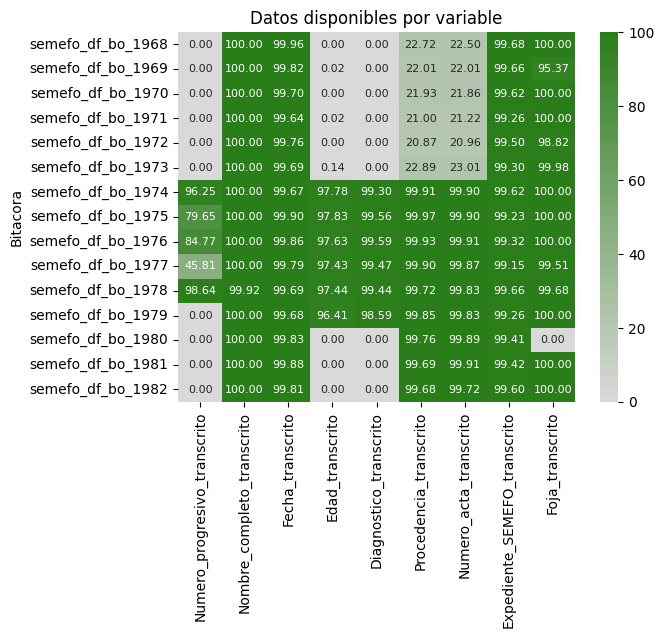

In [5]:
ingresos_anuales = df['Bitacora_ingresos'].value_counts().sort_index()

df_notnan['Bitacora'] = df['Bitacora_ingresos']
df_notnan_anual = df_notnan.groupby('Bitacora').sum().divide( ingresos_anuales, axis=0 )
sns.heatmap(df_notnan_anual*100, cmap=gray_to_green, annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title(f"Datos disponibles por variable")
plt.show()

Ignorando las variables que no fueron capturadas en el año

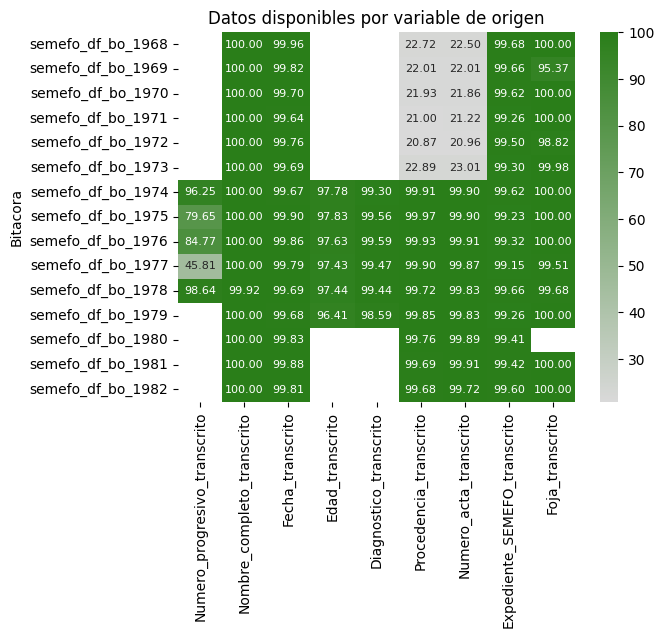

In [6]:
dic_miss_año = { 'Numero_progresivo_transcrito': ['1968','1969','1970','1971','1972','1973','1979','1980','1981','1982'],
                'Edad_transcrito': ['1968','1969','1970','1971','1972','1973','1980','1981','1982'],
                'Diagnostico_transcrito': ['1968','1969','1970','1971','1972','1973','1980','1981','1982'],
                'Foja_transcrito': ['1980'] }  
for col, años in dic_miss_año.items():
    df_notnan.loc[ df_notnan['Bitacora'].isin([f"semefo_df_bo_{a}" for a in años]), col] = nan
df_notnan

df_notnan_anual = df_notnan.groupby('Bitacora', dropna=False) \
                            .apply(lambda x: x.sum(skipna=False)) \
                            .divide( ingresos_anuales, axis=0 )
sns.heatmap(df_notnan_anual*100, cmap=gray_to_green, annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title(f"Datos disponibles por variable de origen")
#plt.savefig("imagenes/BO_VariableFaltante+Año.svg")
plt.show()

Correlación entre faltantes
* Existe una correlación alta  (0.996) entre la falta de procedencia y de acta.
* Existe una correlación debil entre la falta del nombre con la fecha (0.253) y el exp semefo (0.162)


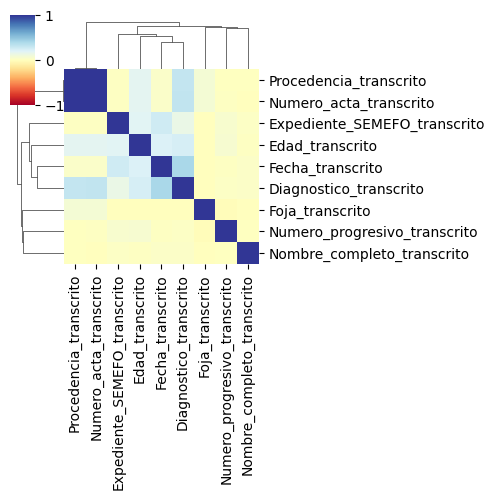

In [7]:
sns.clustermap(df_notnan.drop('Bitacora', axis=1).corr(), vmin=-1, vmax=1, cmap='RdYlBu', figsize=(5,5))
plt.show()

### Filas con más datos faltantes

* Casos donde hay número progresivo o foja pero ningun dato
* Casos donde solo hay nombre, muchas veces solo apellido
* Casos sin fecha pero con expediente

En general no parece haber un patrón, la cantidad de datos esta fuertemente asociada a que campos se capturaron ese año

In [8]:
df_notnan = (df[col_trans]!='S-D')
df_notnan['Bitacora'] = df['Bitacora_ingresos']

dic_miss_año = { 'Numero_progresivo_transcrito': ['1968','1969','1970','1971','1972','1973','1979','1980','1981','1982'],
                'Edad_transcrito': ['1968','1969','1970','1971','1972','1973','1980','1981','1982'],
                'Diagnostico_transcrito': ['1968','1969','1970','1971','1972','1973','1980','1981','1982'],
                'Foja_transcrito': ['1980'] }  
for col, años in dic_miss_año.items():
    años = [f"semefo_df_bo_{a}" for a in años]
    df_notnan.loc[ df_notnan['Bitacora'].isin(años), col] = nan

df_notnan_row = df_notnan.drop('Bitacora', axis=1).sum(axis=1).to_frame()
df_notnan_row.value_counts().sort_index()

0
1        6
2       58
3      459
4    25153
5     7900
6    22190
7      615
8    14044
9    26400
Name: count, dtype: int64

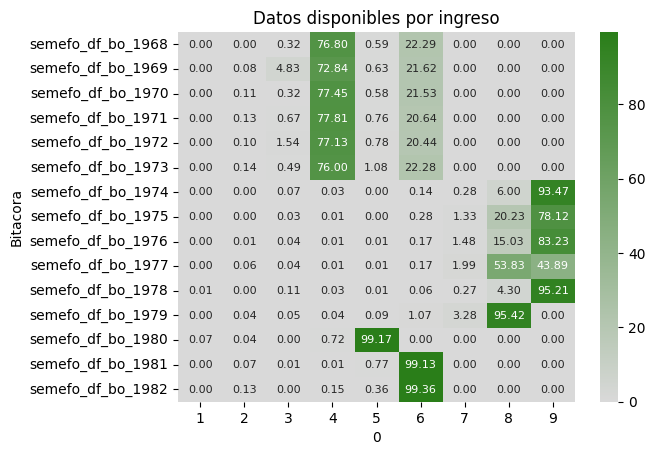

In [9]:
df_notnan_row['Bitacora'] = df['Bitacora_ingresos']
df_notnan_row_anual = df_notnan_row.pivot_table(columns=0, index='Bitacora', aggfunc='size')
df_notnan_row_anual = df_notnan_row_anual.divide(ingresos_anuales, axis=0)
sns.heatmap(df_notnan_row_anual*100, cmap=gray_to_green, annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title(f"Datos disponibles por ingreso")
plt.show()

### Faltantes por tipo de restos

* De 1968 a 1973 faltan procedencia/acta para cadáveres conocidos
* De 1974 a 1979 faltan edades para miembros
* No todos los años hay restos oseos


Cadáver conocido


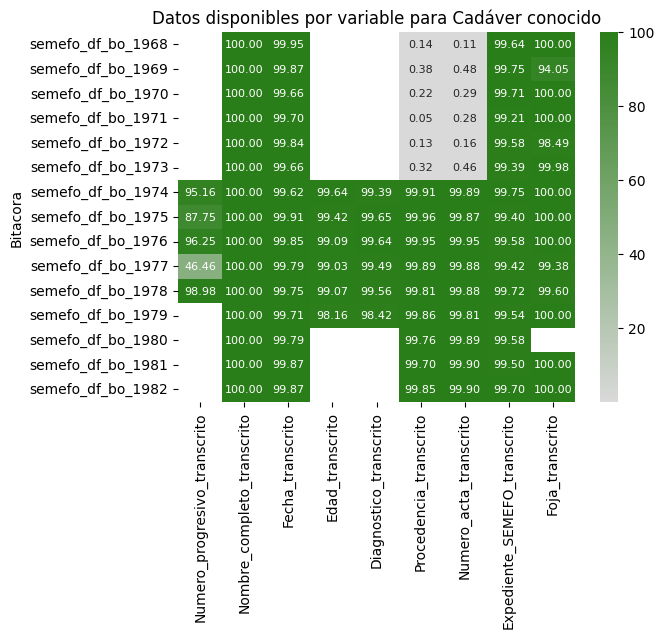

Cadáver desconocido


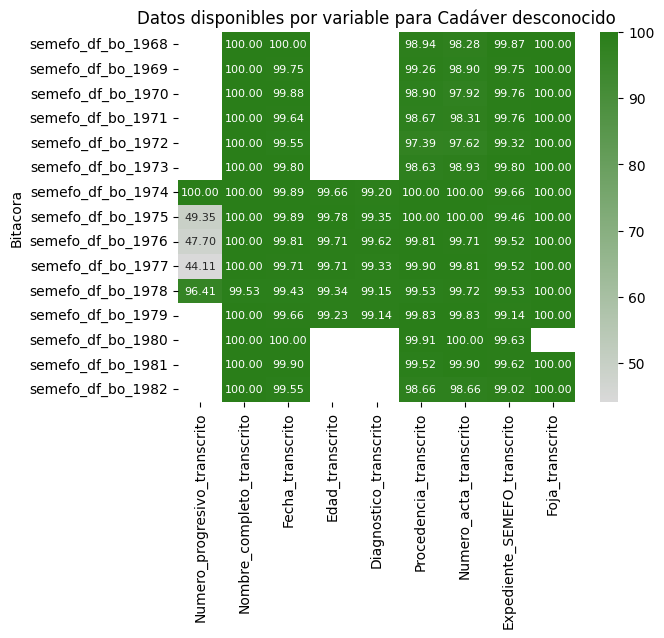

Miembros


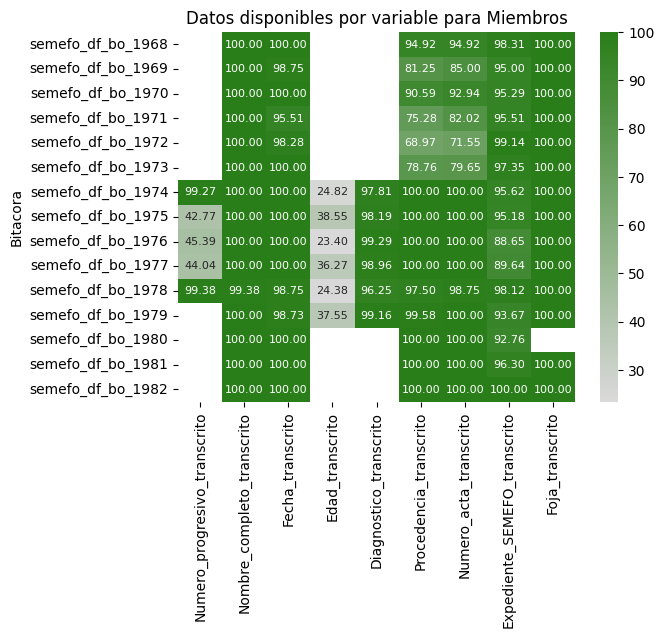

Feto


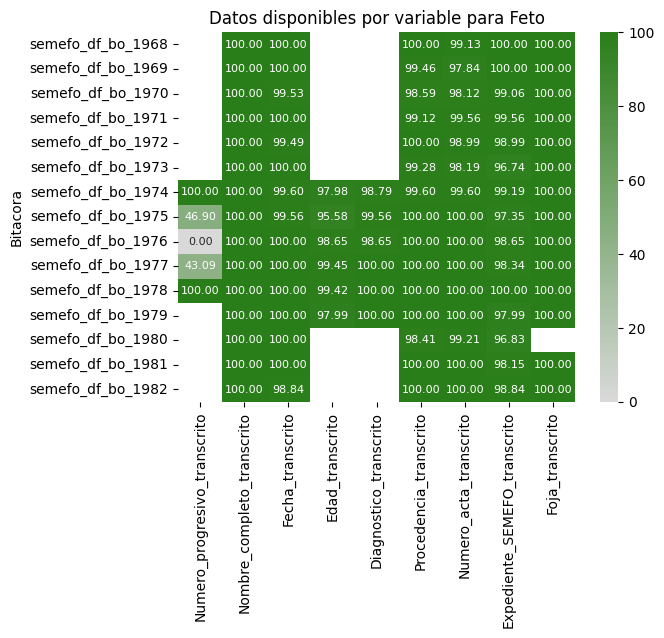

Restos óseos


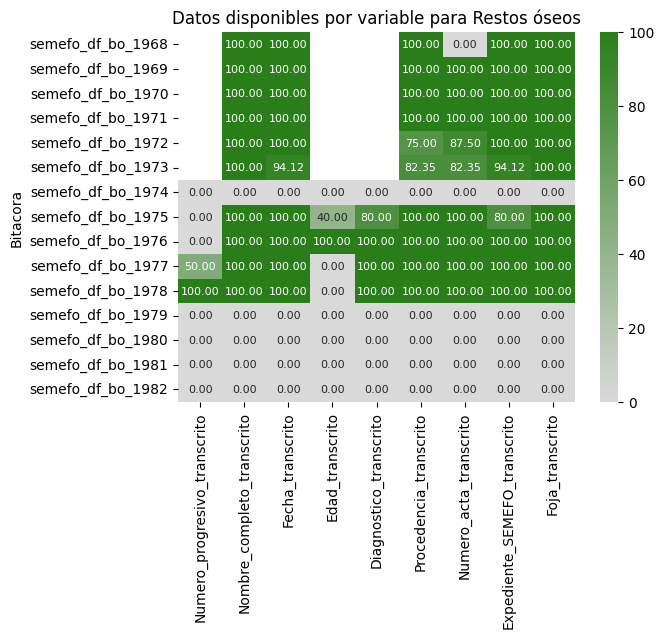

Recién nacido


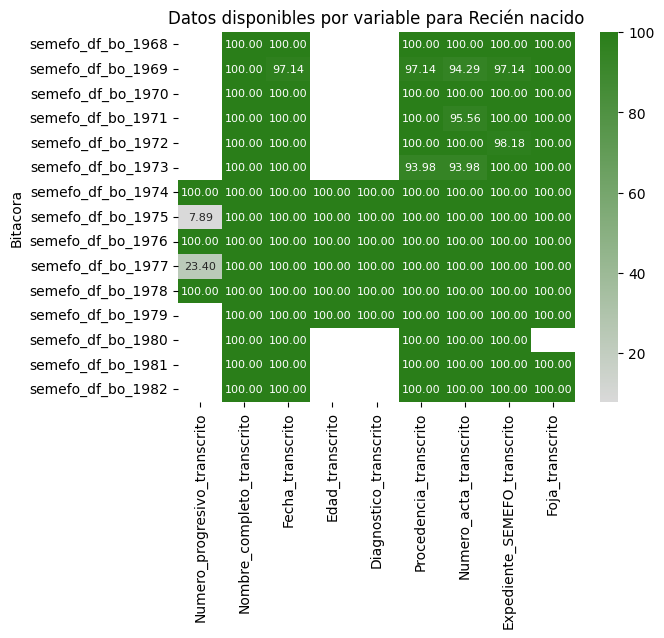

In [10]:
for tipo in df['Tipo_restos'].unique():
    print(tipo)
    ingresos_anuales_tipo = df.loc[df['Tipo_restos']==tipo,'Bitacora_ingresos'].value_counts().sort_index()
    ingresos_anuales_tipo = ingresos_anuales_tipo.replace({0:1.0})
    data = df_notnan[df['Tipo_restos']==tipo]
    data_anual = data.groupby('Bitacora', dropna=False) \
                     .apply(lambda x: x.sum(skipna=False)) \
                     .div( ingresos_anuales_tipo, axis=0 )
    for col in data_anual.columns:
        data_anual[col] = pd.to_numeric(data_anual[col]*100)
    sns.heatmap(data_anual, cmap=gray_to_green, annot=True, fmt=".2f", annot_kws={"size": 8})
    plt.title(f"Datos disponibles por variable para {tipo}")
    plt.show()

## Resumen estadístico

**Tipo_restos**

In [11]:
categorical_to_freq_and_percentage(df['Tipo_restos']).to_frame().transpose()

Tipo_restos,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos
0,76756 (79.273%),14479 (14.954%),633 (0.654%),2844 (2.937%),2065 (2.133%),48 (0.05%)


**Nombre**

In [12]:
string_summary(df['Nombre_completo_transcrito'], df['Tipo_restos'], 
               dropna=False, top_n=5,
               nan_str='Sin datos*', other_str='Otro*',
               percen_round=3, pretty_display=True)
''

,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos
0,hernandez hernandez jesus 7 (0.007%),desconocido 12820 (13.24%),r. nacido 224 (0.231%),feto 2609 (2.695%),nombre confidencial 1880 (1.942%),osamenta 30 (0.031%)
1,hernandez hernandez antonio 6 (0.006%),desconocida 1291 (1.333%),recien nacido 105 (0.108%),nombre confidencial 202 (0.209%),restos humanos 26 (0.027%),restos oseos 8 (0.008%)
2,lopez lopez mario 6 (0.006%),S-D 5 (0.005%),r. nacida 96 (0.099%),fetos 6 (0.006%),placenta 11 (0.011%),desconocido 3 (0.003%)
3,garcia garcia juan 6 (0.006%),desconocido o guadalupe 4 (0.004%),nombre confidencial 72 (0.074%),desconocido (feto) 4 (0.004%),m.i. de: 8 (0.008%),huesos humanos 2 (0.002%)
4,lopez hernandez jose 5 (0.005%),"desconocido o pedro ""n"" 4 (0.004%)",recien nacida 61 (0.063%),desconocida (feto) 2 (0.002%),miembro inferior 7 (0.007%),craneo 2 (0.002%)
5,Otro* 76726 (79.242%),Otro* 355 (0.367%),Otro* 75 (0.077%),Otro* 21 (0.022%),Otro* 133 (0.137%),Otro* 3 (0.003%)


''

**Conocido_desconocido**

In [13]:
categorical_summary(df['Conocido_desconocido'], df['Tipo_restos'], percen_round=3, as_str=True)


,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos,Total
Conocido_desconocido,,,,,,,
Conocido,76756 (79.273%),0 (0.0%),31 (0.032%),31 (0.032%),1795 (1.854%),0 (0.0%),78613 (81.191%)
Desconocido,0 (0.0%),14479 (14.954%),602 (0.622%),2813 (2.905%),270 (0.279%),48 (0.05%),18212 (18.809%)
S-D,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)


**Sexo**

In [14]:
categorical_summary(df['Sexo'], df['Tipo_restos'], percen_round=3, as_str=True)


,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos,Total
Sexo,,,,,,,
Femenino,17923 (18.511%),1580 (1.632%),251 (0.259%),462 (0.477%),384 (0.397%),1 (0.001%),20601 (21.277%)
Masculino,58337 (60.25%),12845 (13.266%),379 (0.391%),662 (0.684%),1511 (1.561%),7 (0.007%),73741 (76.159%)
S-D,496 (0.512%),54 (0.056%),3 (0.003%),1720 (1.776%),170 (0.176%),40 (0.041%),2483 (2.564%)


**Edad**

In [15]:
numeric_summary(df['Edad_estandar'],df['Tipo_restos'],percen_round=3)

,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos,All
count,32348,6094,223,1174,329,3,40171
mean,35.845,40.058,0,0,35.587,26,35.235
std,22.084,17.539,0,0,19.799,12.49,22.127
min,0,0,0,0,0,16,0
25%,20,28,0,0,20,19,20
50%,33,40,0,0,30,22,34
75%,52,50,0,0,48,31,50
max,108,90,0,0,91,40,108


**Diagnostico**

In [16]:
string_summary(df['Diagnostico_extendido'], df['Tipo_restos'], 
               dropna=False, top_n=6,
               nan_str='Sin datos*', other_str='Otro*',
               percen_round=3, pretty_display=True)
''

,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos
0,Sin datos* 44319 (45.772%),Sin datos* 8408 (8.684%),Sin datos* 411 (0.424%),Sin datos* 1654 (1.708%),Sin datos* 1050 (1.084%),Sin datos* 40 (0.041%)
1,traumatismo multiple 6087 (6.287%),traumatismo multiple 1427 (1.474%),asfixia neo natorum 75 (0.077%),expulsion prematura del seno materno 542 (0.56%),amputacion quirurgica por traumatismo 602 (0.622%),indeterminado 3 (0.003%)
2,traumatismo craneo encefalico 5188 (5.358%),traumatismo craneo encefalico 775 (0.8%),bronconeumonia 29 (0.03%),asfixia neo natorum 461 (0.476%),gangrena 45 (0.046%),traumatismo craneo encefalico 2 (0.002%)
3,bronconeumonia 1147 (1.185%),bronconeumonia 676 (0.698%),asfixia por estrangulacion 16 (0.017%),indeterminado 36 (0.037%),traumatismo miembro 33 (0.034%),no copias 1 (0.001%)
4,congestion visceral generalizada 1136 (1.173%),bronconeumonia+cirrosis hepatica 425 (0.439%),traumatismo craneo encefalico 13 (0.013%),falta cuidado post natales 18 (0.019%),amputacion quirurgica por traumatismo+gangrena 30 (0.031%),traumatismo cervico 1 (0.001%)
5,traumatismo craneo torax 1029 (1.063%),congestion visceral generalizada 191 (0.197%),bronconeumonia+enteritis 7 (0.007%),traumatismo craneo encefalico 14 (0.014%),amputacion traumatica 29 (0.03%),herida arma fuego craneo 1 (0.001%)
6,Otro* 17850 (18.435%),Otro* 2577 (2.662%),Otro* 82 (0.085%),Otro* 119 (0.123%),Otro* 276 (0.285%),Otro* 0 (0.0%)


''

In [46]:
string_summary(df['Diagnostico_clasificacion'], df['Tipo_restos'], 
               dropna=False, top_n=6,
               nan_str='Sin datos*', other_str='Otro*',
               percen_round=3, pretty_display=True)
''

,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos
0,Sin datos* 47194 (48.742%),Sin datos* 8769 (9.057%),Sin datos* 435 (0.449%),Sin datos* 1729 (1.786%),Sin datos* 1115 (1.152%),Sin datos* 44 (0.045%)
1,Trauma 17169 (17.732%),Trauma 2829 (2.922%),"Embarazo, parto y puerperio 82 (0.085%)","Embarazo, parto y puerperio 1029 (1.063%)",Amputación 679 (0.701%),Trauma 3 (0.003%)
2,Causas externas de morbilidad y de mortalidad 3921 (4.05%),Enfermedades del sistema respiratorio 835 (0.862%),Causas externas de morbilidad y de mortalidad 34 (0.035%),Causas externas de morbilidad y de mortalidad 28 (0.029%),Amputación+Enfermedades de la piel y del tejido subcutáneo 57 (0.059%),Herida por arma de fuego 1 (0.001%)
3,Herida por arma de fuego 3115 (3.217%),Enfermedades del sistema digestivo 689 (0.712%),Enfermedades del sistema respiratorio 32 (0.033%),Trauma 25 (0.026%),Enfermedades de la piel y del tejido subcutáneo 53 (0.055%),Amputación+Ciertas enfermedades infecciosas y parasitarias 0 (0.0%)
4,Enfermedades del sistema respiratorio 1544 (1.595%),Causas externas de morbilidad y de mortalidad 458 (0.473%),Trauma 29 (0.03%),Enfermedades del sistema respiratorio 12 (0.012%),Trauma 43 (0.044%),Amputación+Enfermedades de la piel y del tejido subcutáneo 0 (0.0%)
5,Enfermedades del sistema digestivo 970 (1.002%),Herida por arma de fuego 263 (0.272%),Enfermedades del sistema digestivo 10 (0.01%),"Malformaciones congénitas, deformidades y anomalías cromosómicas 8 (0.008%)",Amputación+Causas externas de morbilidad y de mortalidad 27 (0.028%),Amputación+Enfermedades del sistema circulatorio 0 (0.0%)
6,Otro* 2843 (2.936%),Otro* 636 (0.657%),Otro* 11 (0.011%),Otro* 13 (0.013%),Otro* 91 (0.094%),Otro* 0 (0.0%)


''

**Procedencia**

In [17]:
string_summary(df['Procedencia_extendido'], df['Tipo_restos'], 
               dropna=False, top_n=5,
               nan_str='Sin datos*', other_str='Otro*',
               percen_round=3, pretty_display=True)
''

,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos
0,Sin datos* 25524 (26.361%),Coord Territorial 1 Venustiano Carranza (Col Merced) 1179 (1.218%),Coord Territorial 2 Gustavo A Madero (Col Aragon La Villa) 88 (0.091%),Coord Territorial 2 Gustavo A Madero (Col Aragon La Villa) 310 (0.32%),Coord Territorial 2 Coyoacan (Col Romero de Terreros) 425 (0.439%),Coord Territorial 2 Azcapotzalco (Col Del Maestro) 8 (0.008%)
1,Cruz Roja (Col Polanco) 3983 (4.114%),Coord Territorial 1 Cuauhtemoc (Col San Simon Tolnahuac) 1170 (1.208%),Coord Territorial 1 Coyoacan (Col Romero de Terreros) 41 (0.042%),Coord Territorial 1 Cuauhtemoc (Col San Simon Tolnahuac) 173 (0.179%),Hospital Balbuena (Col Jardin Balbuena) 275 (0.284%),Coord Territorial 2 Gustavo A Madero (Col Aragon La Villa) 7 (0.007%)
2,Hospital Balbuena (Col Jardin Balbuena) 3954 (4.084%),Coord Territorial 2 Gustavo A Madero (Col Aragon La Villa) 1123 (1.16%),Coord Territorial 1 Iztapalapa (Barrio de San Lucas) 41 (0.042%),Coord Territorial 1 Iztapalapa (Barrio de San Lucas) 137 (0.141%),Hospital Xoco (Col General Anaya) 199 (0.206%),Coord Territorial 1 Coyoacan (Col Romero de Terreros) 5 (0.005%)
3,Coord Territorial 2 Coyoacan (Col Romero de Terreros) 3166 (3.27%),Hospital Balbuena (Col Jardin Balbuena) 1116 (1.153%),Coord Territorial 1 Cuauhtemoc (Col San Simon Tolnahuac) 36 (0.037%),Coord Territorial 1 Coyoacan (Col Romero de Terreros) 134 (0.138%),Cruz Roja (Col Polanco) 176 (0.182%),Sin datos* 5 (0.005%)
4,Hospital la Villa (Col Granjas Modernas) 2822 (2.915%),Cruz Roja (Col Polanco) 686 (0.708%),Coord Territorial 6 Cuauhtemoc (Col Centro) 32 (0.033%),Coord Territorial 2 Azcapotzalco (Col Del Maestro) 129 (0.133%),Hospital Ruben Leñero (Col Santo Tomas) 136 (0.14%),Coord Territorial 8 Cuauhtemoc (Col Obrera) 4 (0.004%)
5,Otro* 37307 (38.53%),Otro* 9205 (9.507%),Otro* 395 (0.408%),Otro* 1961 (2.025%),Otro* 854 (0.882%),Otro* 19 (0.02%)


''

### Aluvial

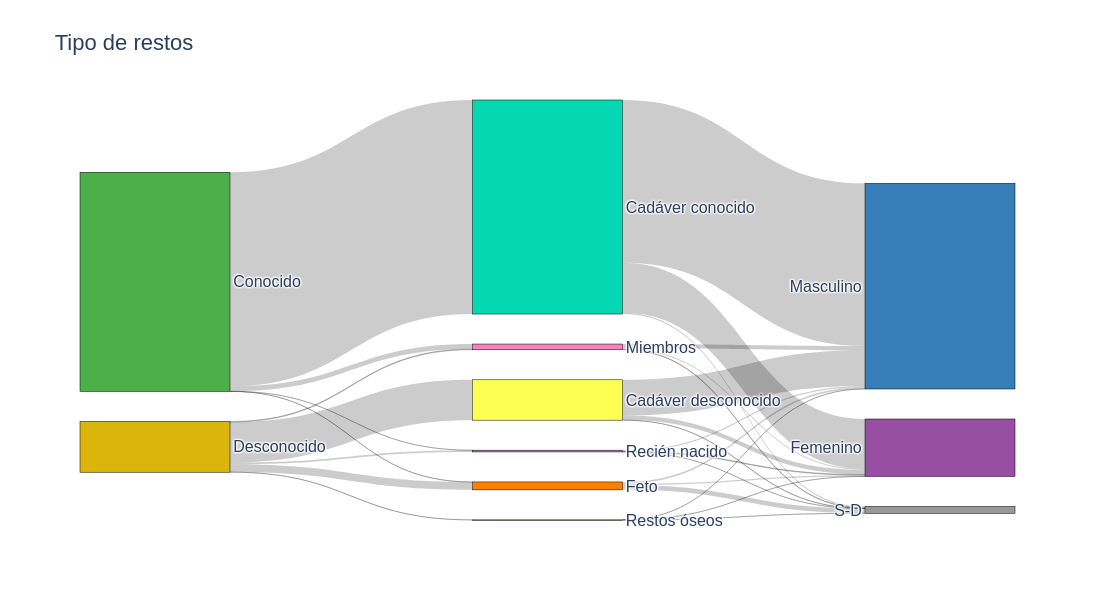

In [18]:
import plotly.graph_objects as go

cols = ['Conocido_desconocido', 'Tipo_restos', 'Sexo']

data = df[cols].value_counts().reset_index()
data.columns = cols + ['freq']
data.head()

# Step 1: Build all unique labels
labels = pd.unique(data[cols].values.ravel()).tolist()
label_index = {l: i for i, l in enumerate(labels)}
label_colors = [dic_color.get(label, 'lightgray') for label in labels]

# Step 2: Create source-target pairs
links = list()
for s,t in zip(cols, cols[1:]):
    link = data.groupby([s,t])['freq'].sum().reset_index()
    link['source'] = link[s].map(label_index)
    link['target'] = link[t].map(label_index)
    links.append( link[['source','target','freq']] )
    
links = pd.concat(links)
links.head()

# Step 3: Build the Sankey diagram
fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=30,
        thickness=150,
        line=dict(color="black", width=0.5),
        label=labels,
        color=label_colors
    ),
    link=dict(
        source=links['source'],
        target=links['target'],
        value=links['freq']
    )
)])

fig.update_layout(title_text="Tipo de restos", 
                  width=900,height=600,
                  font_size=16)
fig.show()

## Sexo y Edad

'Sexo', 
'Edad_transcrito', 
'Edad_estandar',
'Edad_grupo',

Cargando archivos de referencia del INEGI

Datos tomados de:
* Secretaría de Programación y Presupuesto. (1982). Defunciones registradas en la República Mexicana, 1933-1975. Coordinación General de los Servicios Nacionales de Estadística, Geografía e Informática. ISBN 968-809-593-1.
* Instituto Nacional de Estadística, Geografía e Informática. (1994). Defunciones en los Estados Unidos Mexicanos, 1976-1992. INEGI. ISBN 970-13-0098-X.

In [19]:
df_inegi_edad = pd.read_csv('data_raw/INEGI_defunciones_sexo_1966-1984.csv', index_col='Edad_grupo')
df_inegi_edad

FileNotFoundError: [Errno 2] No such file or directory: 'data_raw/INEGI_defunciones_sexo_1966-1984.csv'

### Ingresos anuales por sexo

In [20]:
dic_colors = {'Masculino (SEMEFO)':'#377eb8','Femenino (SEMEFO)':'#984ea3','S-D (SEMEFO)':'#999999',
              'Masculino (DF)':'#80b1d3','Femenino (DF)':'#bebada','S-D (DF)':'#d9d9d9'}

df_año_sexo = df.pivot_table(index='Bitacora_ingresos', columns='Sexo', aggfunc='size')
df_año_sexo.index = [int(y.replace('semefo_df_bo_','')) for y in df_año_sexo.index]
df_año_sexo.columns = ['Femenino (SEMEFO)','Masculino (SEMEFO)','S-D (SEMEFO)',]
df_año_sexo

df_año_sexo_inegi = df_inegi_edad.loc[['Femenino','Masculino','S-D']].transpose().drop('Sexo')
df_año_sexo_inegi.index = [int(i) for i in df_año_sexo_inegi.index]
df_año_sexo_inegi.columns = ['Masculino (DF)','Femenino (DF)','S-D (DF)']
df_año_sexo_inegi

# Create the figure and axes object
fig, ax = plt.subplots()

# Plot the first area plot
df_año_sexo_inegi.plot.area(ax=ax, alpha=0.5, color=dic_colors)

# Plot the second area plot on the same axes
df_año_sexo.plot.area(ax=ax, alpha=0.9, color=dic_colors)

# Add labels and title
ax.set_xlabel('Año')
ax.set_ylabel('Defunciones')
ax.set_title('Defunciones vs ingresos al SEMEFO')

# Display the legend
ax.legend()
ax.legend(loc='center left')
ax.set_xticklabels([int(x) for x in ax.get_xticks()]) # Remove negative sign from tick labels
# Plotting
plt.tight_layout()
#plt.savefig("imagenes/BO_Año+Sexo_DF+SEMEFO.svg")
plt.show()

NameError: name 'df_inegi_edad' is not defined

### Distribución de edad

Picos en edades terminadas en 0 o 5

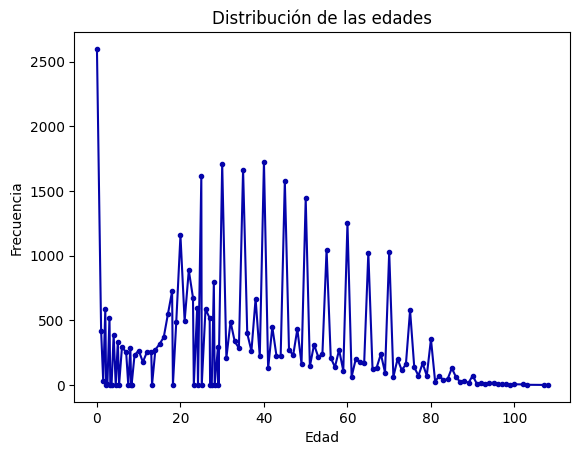

In [21]:
edad_freq = df['Edad_estandar'].value_counts().sort_index()
edad_freq

edad_freq.plot(style='.-', title="Distribución de las edades",
               xlabel='Edad', ylabel='Frecuencia', color='#0504aa'
              )
plt.show()

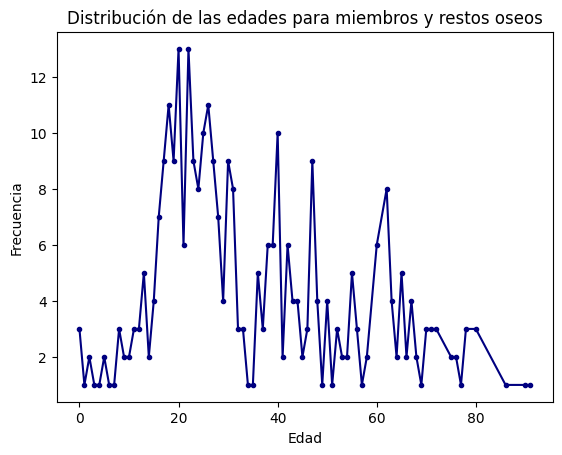

In [22]:
edad_freq = df.loc[df['Tipo_restos'].isin(['Miembros','Restos óseos']),'Edad_estandar'].value_counts().sort_index()
edad_freq

edad_freq.plot(style='.-', title="Distribución de las edades para miembros y restos oseos",
               xlabel='Edad', ylabel='Frecuencia', color='navy'
              )
plt.show()

### Edad vs sexo

In [23]:
# Calcular frecuencia por grupo de edad y sexo
edad_sexo = df[~df['Tipo_restos'].isin(['Miembros','Restos óseos'])] \
                .pivot_table(index='Edad_grupo',columns='Sexo',values='Edad_estandar',aggfunc='count')
#display(edad_sexo)

años_edad = ['1974','1975','1976','1977','1978','1979']
index_edad = ['[0.0, 1.0)', '[1.0, 5.0)', '[5.0, 10.0)', '[10.0, 15.0)', '[15.0, 20.0)', '[20.0, 25.0)', '[25.0, 30.0)', 
              '[30.0, 35.0)', '[35.0, 40.0)', '[40.0, 45.0)', '[45.0, 50.0)', '[50.0, 55.0)', '[55.0, 60.0)', 
              '[60.0, 65.0)', '[65.0, 70.0)', '[70.0, 75.0)', '[75.0, 80.0)', '[80.0, 85.0)', '[85.0, 110.0)']
data = df_inegi_edad.loc[index_edad,['Sexo']+años_edad]
data['Freq']= data[años_edad].sum(axis=1)
data = data.reset_index().pivot(index='Edad_grupo', columns='Sexo', values='Freq').fillna(0)
data = data.loc[index_edad]
display(data)

dic_colors = {'Masculino (SEMEFO)':'#377eb8','Femenino (SEMEFO)':'#984ea3','S-D (SEMEFO)':'#999999',
              'Masculino (DF)':'#80b1d3','Femenino (DF)':'#bebada','S-D (DF)':'#d9d9d9'}

# Set position for each age group
y = range(len(edad_sexo)) 
# Plotting
fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(y, [-val for val in data['Femenino']], color='#bebada', label='Femenino (DF)') # Plot female bars (negative)
ax.barh(y, data['Masculino'], color='#80b1d3', label='Masculino (DF)') # Plot male bars (positive)
ax.barh(y, [-val for val in edad_sexo['Femenino']], color='#984ea3', label='Femenino (SEMEFO)') # Plot female bars (negative)
ax.barh(y, edad_sexo['Masculino'], color='#377eb8', label='Masculino (SEMEFO)') # Plot male bars (positive)
# Y-axis label and formatting
plt.xlim( -15500, 11000 )
ax.set_yticks(y) # Set age groups as y-ticks (on horizontal axis)
ax.set_yticklabels(edad_sexo.index)
# X-axis label and formatting
ax.set_xlabel('Población')
ax.set_title('Defunciones por grupo de edad')
ax.legend(loc='center left')
# Plotting
plt.tight_layout()
#plt.savefig("imagenes/BO_PiramidePoblacional_DF+SEMEFO.svg")
plt.show()

NameError: name 'df_inegi_edad' is not defined

## Fecha
'Fecha_transcrito', 
'Fecha_estandar', 
'Fecha_año', 
'Fecha_mes',
'Fecha_diasemana',

### Ingresos anuales y diarios

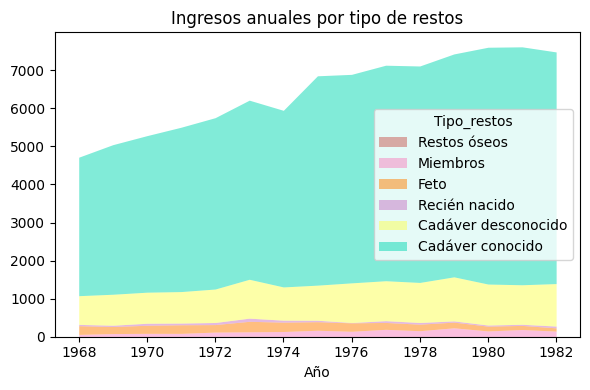

In [24]:
df_año_tipo = df.pivot_table(index='Fecha_año', columns='Tipo_restos', aggfunc='size')
df_año_tipo = df_año_tipo[df['Tipo_restos'].cat.categories].iloc[:, ::-1]
#display( df_año_tipo )

fig, ax = plt.subplots(figsize=(6, 4))
df_año_tipo.plot.area(ax=ax, color=dic_color, linewidth=0, alpha=0.5,)
ax.set_xlabel('Año')
ax.set_title('Ingresos anuales por tipo de restos')
ax.set_xticklabels([x.get_text().replace('.0','') for x in ax.get_xticklabels()]) # Remove negative sign from tick labels
plt.tight_layout()
#plt.savefig("imagenes/BO_TipoRestos+Sexo.svg")
plt.show()

**Ingresos diaros de toda la población**

En total, del 1968-01-01 al 1982-12-31 hay 5479 días
* Todos los días hubo ingresos
* Mediana de 17 ingresos diarios
* Min 2 ingresos, max 46 ingresos en un día

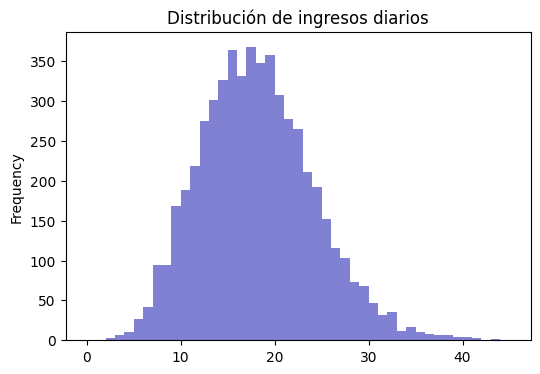

In [25]:
display()

fig, ax = plt.subplots(figsize=(6, 4))
df['Fecha_estandar'].value_counts().plot.hist(ax=ax, color=dic_color['Poblacion'], bins=range(46), alpha=0.5,
                      title='Distribución de ingresos diarios')
plt.show()

**Por tipo de restos**

,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros,Restos óseos,count
count,5479.000000,4844.000000,548.000000,2077.000000,1525.000000,39.000000,5479.000000
mean,13.975908,2.980388,1.153285,1.366875,1.344262,1.205128,17.627122
std,5.212267,1.805487,0.446649,0.669469,0.695062,0.570295,6.060894
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000
25%,10.000000,2.000000,1.000000,1.000000,1.000000,1.000000,13.000000
50%,14.000000,3.000000,1.000000,1.000000,1.000000,1.000000,17.000000
75%,17.000000,4.000000,1.000000,2.000000,2.000000,1.000000,21.000000
max,36.000000,18.000000,5.000000,6.000000,9.000000,3.000000,46.000000


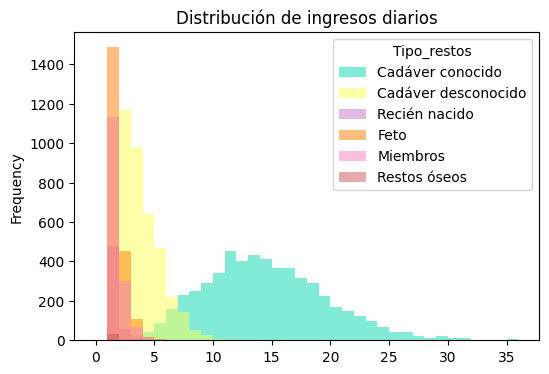

In [26]:
ing_diarios = df.pivot_table(index='Fecha_estandar', columns='Tipo_restos', aggfunc='size').sort_index().replace(0,nan)
display(pd.concat( [ing_diarios.describe(),df['Fecha_estandar'].value_counts().describe()], axis=1 ))

fig, ax = plt.subplots(figsize=(6, 4))
ing_diarios.plot.hist(ax=ax, color=dic_color, bins=range(37), alpha=0.5,
                      title='Distribución de ingresos diarios')

#plt.savefig("imagenes/BO_Distribucion_TipoRestos+IngresosDiarios.svg")
plt.show()

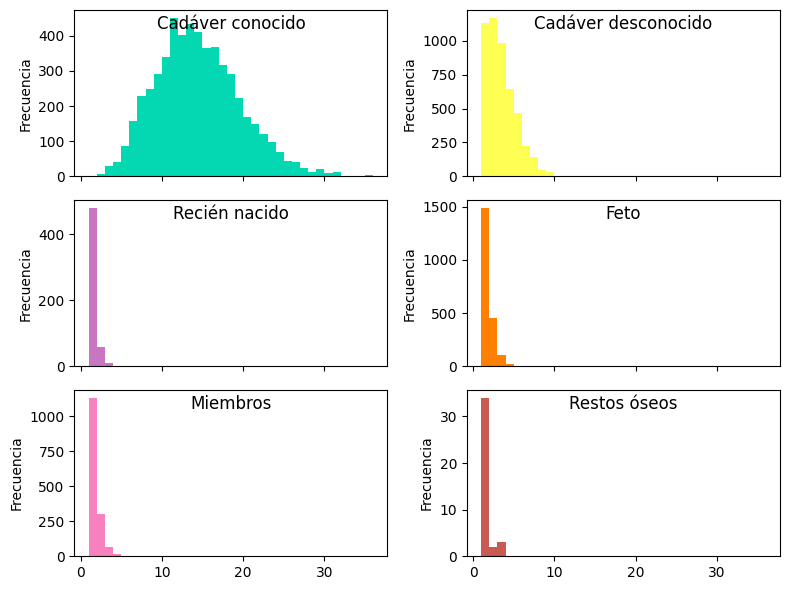

In [27]:
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(8, 6), sharex=True)
axes = axes.flatten()

for ax,col in zip(axes,ing_diarios.columns):
    ing_diarios[col].plot.hist(ax=ax, color=dic_color[col], bins=range(1,37), ylabel='Frecuencia' )
    ax.set_title(col, y=1.0, pad=-14)
    ax.set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()

### Periodicidad entre años y semana



**Mediana de ingresos semanales**

In [28]:
ingresos_semanales = df.pivot_table(index='Fecha_semana', columns='Fecha_año', aggfunc='size').sort_index()
ingresos_semanales.median()

Fecha_año
1968.0     90.0
1969.0     94.0
1970.0     99.0
1971.0    102.0
1972.0    110.0
1973.0    117.0
1974.0    114.0
1975.0    132.0
1976.0    130.0
1977.0    134.0
1978.0    136.0
1979.0    142.0
1980.0    144.0
1981.0    146.0
1982.0    143.0
dtype: float64

* Incremento en ingresos en diciembre y primera de enero

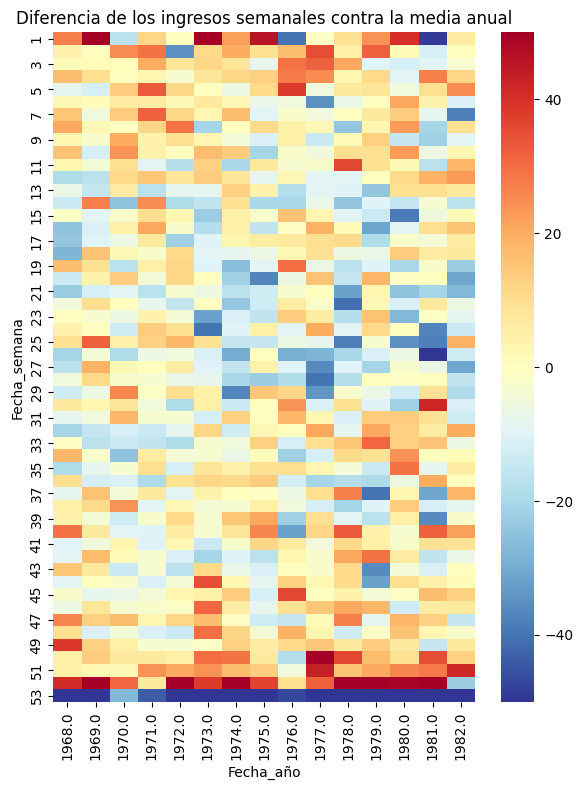

In [29]:
fig, ax = plt.subplots(figsize=(6, 8))
sns.heatmap(ax=ax, data=ingresos_semanales-ingresos_semanales.median(), vmin=-50, vmax=50, cmap='RdYlBu_r', )
plt.title('Diferencia de los ingresos semanales contra la media anual')
plt.tight_layout()
plt.show()

In [30]:
ingresos_semanales.median()

Fecha_año
1968.0     90.0
1969.0     94.0
1970.0     99.0
1971.0    102.0
1972.0    110.0
1973.0    117.0
1974.0    114.0
1975.0    132.0
1976.0    130.0
1977.0    134.0
1978.0    136.0
1979.0    142.0
1980.0    144.0
1981.0    146.0
1982.0    143.0
dtype: float64

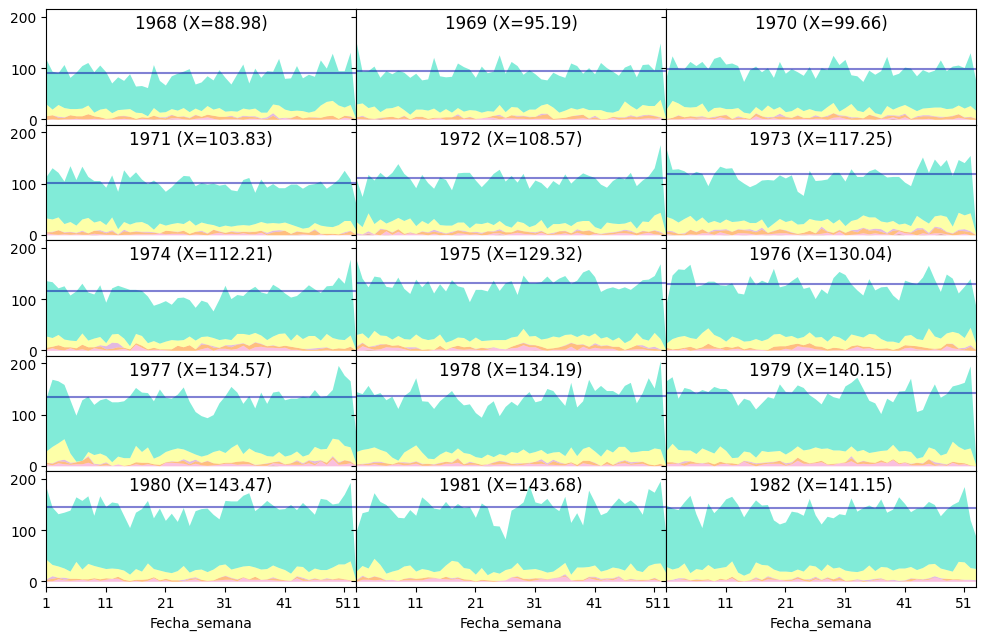

In [31]:
ncols = 3
fig, axes = plt.subplots(nrows=round(df['Fecha_año'].nunique()/ncols), ncols=ncols, 
                         figsize=(12,df['Fecha_año'].nunique()*1.5/ncols), 
                         sharex=True, sharey=True, )
for ax,año in zip(axes.flatten(),df['Fecha_año'].sort_values().dropna().unique()):
    data = df.loc[df['Fecha_año']==año,['Fecha_semana','Tipo_restos']]
    mediana_semanal = data.groupby('Fecha_semana', observed=True).size().median()
    data = data.pivot_table(index='Fecha_semana',columns='Tipo_restos',aggfunc='size').iloc[:, ::-1]
    data.plot.area(ax=ax, color=dic_color, linewidth=0, alpha=0.5)
    ax.axhline(y=mediana_semanal, color=dic_color['Poblacion'], alpha=0.5)
    ax.margins(x=0)
    ax.set_title(f"{int(año)} (X={data.sum(axis=1).mean().round(2)})", y=1.0, pad=-14)
    ax.get_legend().remove()
plt.subplots_adjust(wspace=0, hspace=0)
#plt.savefig("imagenes/BO_SemanaAño+TipoRestos.svg")
plt.show()

### Ingresos por dia de la semana

In [32]:
df['Fecha_diasemana'].value_counts()

Fecha_diasemana
Lunes        16578
Martes       15090
Miercoles    13615
Jueves       13132
Domingo      12731
Sábado       12727
Viernes      12706
Name: count, dtype: int64

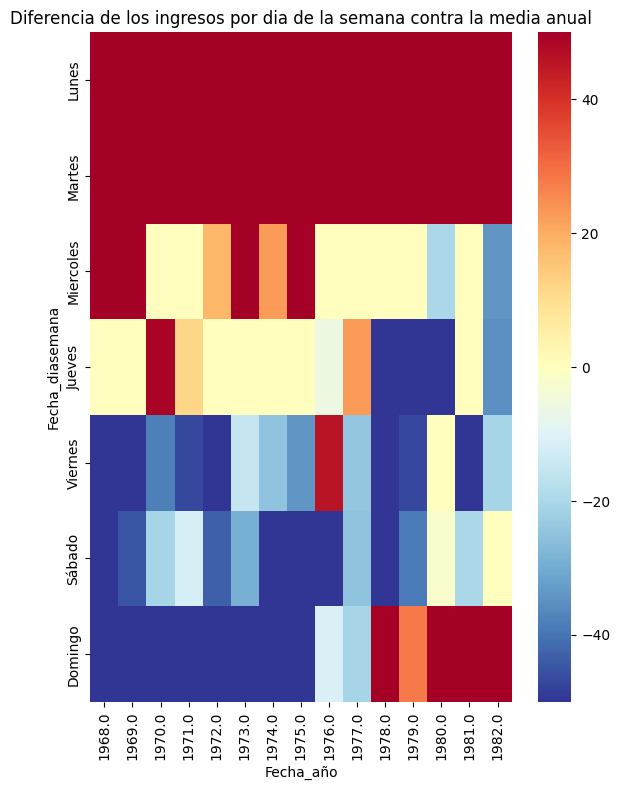

In [33]:
ingresos_diasem = df.pivot_table(index='Fecha_diasemana', columns='Fecha_año', aggfunc='size').sort_index()

fig, ax = plt.subplots(figsize=(6, 8))
sns.heatmap(ax=ax, data=ingresos_diasem-ingresos_diasem.median(), vmin=-50, vmax=50, cmap='RdYlBu_r', )
plt.title('Diferencia de los ingresos por dia de la semana contra la media anual')
plt.tight_layout()
#plt.savefig("imagenes/BO_DiaSemana+Ingresos.svg")
plt.show()

### Ingresos fuera de año y patrón

* Sin fecha de ingreso
* Errores de conversión de fecha (29 de febrero por ejemplo)
* Ultimo mes del año anterior
* Primer mes del año posterior
* Casos especiales
    * En la bitacora de 1973 hay varios de 1974, consecutivos de la v a la x
    * Casos del futuro
    * Podría ser cuestión de transcripción
    
    

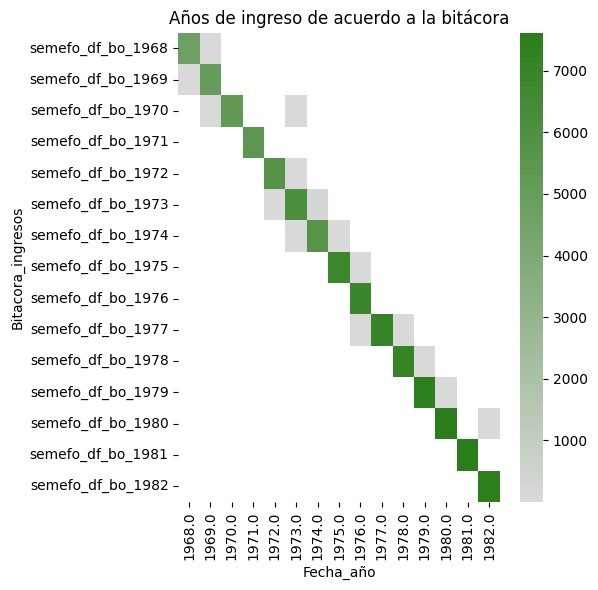

In [34]:
data = df.pivot_table(index='Bitacora_ingresos', columns='Fecha_año', aggfunc='size').replace(0,nan).sort_index()
fig, ax = plt.subplots(figsize=(6, 6))
sns.heatmap(ax=ax, data=data, cmap=gray_to_green, )
plt.title('Años de ingreso de acuerdo a la bitácora')
plt.tight_layout()
plt.show()

In [35]:
for bit in df['Bitacora_ingresos'].unique():
    print(bit)
    año_bit = int(bit.replace('semefo_df_bo_',''))
    display(bit, df[(df['Bitacora_ingresos']==bit) & (df['Fecha_año']!=año_bit) & (df['Fecha_transcrito']!='S-D')] )
    print('\n')
    

semefo_df_bo_1968


'semefo_df_bo_1968'

,Numero_progresivo_transcrito,Nombre_completo_transcrito,Primer_apellido,Segundo_apellido,Nombres_propios,Fecha_transcrito,Fecha_estandar,Fecha_año,Fecha_mes,Fecha_semana,...,Procedencia_transcrito,Procedencia_estandar,Procedencia_extendido,Procedencia_alcaldia,Procedencia_clasificacion,Numero_acta_transcrito,Expediente_SEMEFO_transcrito,Bitacora_ingresos,Foja_transcrito,Observaciones
ID,,,,,,,,,,,,,,,,,,,,,
BO_1968_04658,S-D,valadez alanis francisco,valadez,alanis,francisco,1969-01-01,1969-01-01,1969.0,1.0,1,...,S-D,NaN,NaN,NaN,NaN,S-D,4875,semefo_df_bo_1968,121 reverso,se indica que fue entregado en 1969.
BO_1968_04659,S-D,vazquez contreras carlos,vazquez,contreras,carlos,1969-07-28,1969-07-28,1969.0,7.0,31,...,S-D,NaN,NaN,NaN,NaN,S-D,4815,semefo_df_bo_1968,121 reverso,se indica que fue entregado en 1969.




semefo_df_bo_1969


'semefo_df_bo_1969'

...

'semefo_df_bo_1981'

,Numero_progresivo_transcrito,Nombre_completo_transcrito,Primer_apellido,Segundo_apellido,Nombres_propios,Fecha_transcrito,Fecha_estandar,Fecha_año,Fecha_mes,Fecha_semana,...,Procedencia_transcrito,Procedencia_estandar,Procedencia_extendido,Procedencia_alcaldia,Procedencia_clasificacion,Numero_acta_transcrito,Expediente_SEMEFO_transcrito,Bitacora_ingresos,Foja_transcrito,Observaciones
ID,,,,,,,,,,,,,,,,,,,,,
BO_1981_06369,S-D,desconocido,NaN,NaN,NaN,1981-02-31,NaT,NaN,NaN,NaN,...,36,HV,Hospital la Villa (Col Granjas Modernas),Gustavo A Madero,Hospital,154,646,semefo_df_bo_1981,115 reverso,marca de verificacion al final del nombre; pun...
BO_1981_06560,S-D,desconocido,NaN,NaN,NaN,31/04/1981,NaT,NaN,NaN,NaN,...,18,IZC-2,Coord Territorial 2 Iztacalco (Col Gabriel Ram...,Iztacalco,Judicial,841,1860,semefo_df_bo_1981,118 reverso,marca de verificacion al final del nombre. la ...
BO_1981_06561,S-D,desconocido,NaN,NaN,NaN,31/04/1981,NaT,NaN,NaN,NaN,...,18,IZC-2,Coord Territorial 2 Iztacalco (Col Gabriel Ram...,Iztacalco,Judicial,842,1861,semefo_df_bo_1981,118 reverso,marca de verificacion al final del nombre. la ...
BO_1981_06562,S-D,desconocido,NaN,NaN,NaN,31/04/1981,NaT,NaN,NaN,NaN,...,15,GAM-2,Coord Territorial 2 Gustavo A Madero (Col Arag...,Gustavo A Madero,Judicial,455,1865,semefo_df_bo_1981,118 reverso,marca de verificacion al final del nombre. la ...
BO_1981_06577,S-D,desconocido,NaN,NaN,NaN,31/04/1981,NaT,NaN,NaN,NaN,...,36,HV,Hospital la Villa (Col Granjas Modernas),Gustavo A Madero,Hospital,498,1926,semefo_df_bo_1981,119,punto rojo en expediente_semefo. la bitacora o...




semefo_df_bo_1982


'semefo_df_bo_1982'

,Numero_progresivo_transcrito,Nombre_completo_transcrito,Primer_apellido,Segundo_apellido,Nombres_propios,Fecha_transcrito,Fecha_estandar,Fecha_año,Fecha_mes,Fecha_semana,...,Procedencia_transcrito,Procedencia_estandar,Procedencia_extendido,Procedencia_alcaldia,Procedencia_clasificacion,Numero_acta_transcrito,Expediente_SEMEFO_transcrito,Bitacora_ingresos,Foja_transcrito,Observaciones
ID,,,,,,,,,,,,,,,,,,,,,


## Nombre
'Nombre_completo_transcrito',
'Primer_apellido', 
'Segundo_apellido', 
'Nombres_propios',

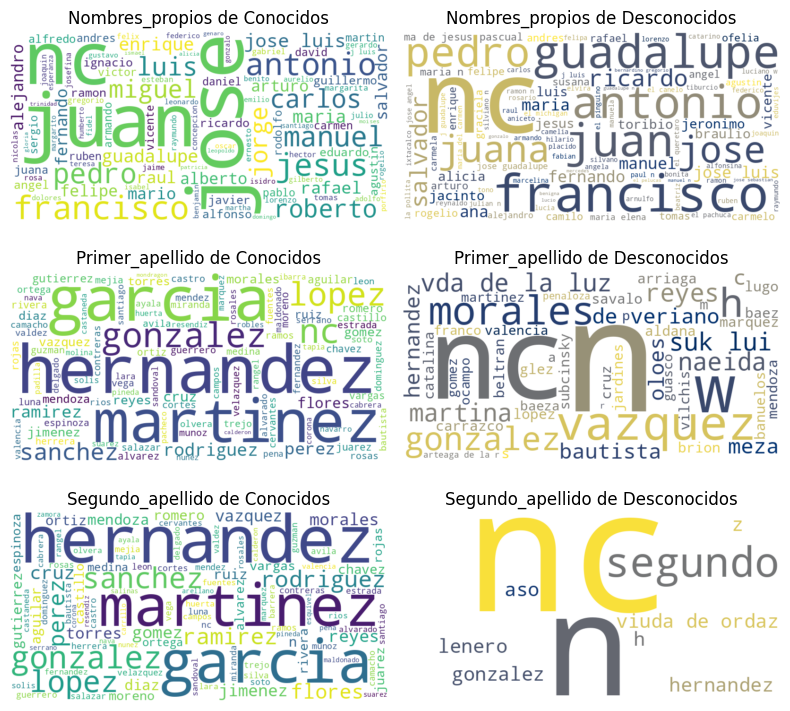

In [36]:
cols = ['Nombres_propios','Primer_apellido', 'Segundo_apellido', ]
fig, axes = plt.subplots(nrows=len(cols), ncols=2, figsize=(8, 2.5*len(cols)), sharex=True)

for i,col in enumerate(cols): 
    freq_cono = df.loc[df['Conocido_desconocido']=='Conocido',col] \
                  .apply(simplify_string, remove_special=True) \
                  .value_counts().head(100).to_dict()
    wordcloud = WordCloud(width=800, height=400,
                          relative_scaling=0.5, 
                          background_color='white') \
                          .generate_from_frequencies(freq_cono)
    # Display the word cloud
    axes[i,0].imshow(wordcloud, interpolation='bilinear')
    axes[i,0].axis('off')
    axes[i,0].set_title(f"{col} de Conocidos")
    
    freq_des = df.loc[df['Conocido_desconocido']=='Desconocido',col] \
                  .apply(simplify_string, remove_special=True) \
                  .value_counts().head(100).to_dict()
    wordcloud = WordCloud(width=800, height=400,
                          relative_scaling=0.5, 
                          colormap='cividis', background_color='white') \
                          .generate_from_frequencies(freq_des)
    # Display the word cloud
    axes[i,1].imshow(wordcloud, interpolation='bilinear')
    axes[i,1].axis('off')
    axes[i,1].set_title(f"{col} de Desconocidos")
plt.tight_layout()
#plt.savefig("imagenes/BO_Wordcloud_Nombre.svg")
plt.show()

## Procedencia
'Procedencia_transcrito', 
'Procedencia_estandar',
'Procedencia_extendido', 
'Procedencia_alcaldia',
'Numero_acta_transcrito'
       
* Procedencia por tipo restos,  sexo edad
* Mapa procedencia
* Procedencia por tipo, mp, hosp, mp association a hosp, otro

In [37]:
grouper = df['Tipo_restos'].astype(str) +' ' + df['Sexo'].astype(str)


string_summary(df['Procedencia_extendido'], grouper, 
               dropna=False, top_n=5,
               nan_str='Sin datos*', other_str='Otro*',
               percen_round=3, pretty_display=True)
''

,Cadáver conocido Femenino,Cadáver conocido Masculino,Cadáver conocido S-D,Cadáver desconocido Femenino,Cadáver desconocido Masculino,Cadáver desconocido S-D,Feto Femenino,Feto Masculino,Feto S-D,Miembros Femenino,Miembros Masculino,Miembros S-D,Recién nacido Femenino,Recién nacido Masculino,Recién nacido S-D,Restos óseos Femenino,Restos óseos Masculino,Restos óseos S-D
0,Sin datos* 5808 (5.998%),Sin datos* 19374 (20.009%),Sin datos* 342 (0.353%),Coord Territorial 1 Cuauhtemoc (Col San Simon Tolnahuac) 148 (0.153%),Coord Territorial 1 Venustiano Carranza (Col Merced) 1042 (1.076%),Sin datos* 23 (0.024%),Coord Territorial 1 Cuauhtemoc (Col San Simon Tolnahuac) 37 (0.038%),Coord Territorial 2 Gustavo A Madero (Col Aragon La Villa) 55 (0.057%),Coord Territorial 2 Gustavo A Madero (Col Aragon La Villa) 229 (0.237%),Coord Territorial 2 Coyoacan (Col Romero de Terreros) 63 (0.065%),Coord Territorial 2 Coyoacan (Col Romero de Terreros) 349 (0.36%),Coord Territorial 2 Gustavo A Madero (Col Aragon La Villa) 28 (0.029%),Coord Territorial 2 Gustavo A Madero (Col Aragon La Villa) 32 (0.033%),Coord Territorial 2 Gustavo A Madero (Col Aragon La Villa) 56 (0.058%),Coord Territorial 6 Cuauhtemoc (Col Centro) 1.0 (0.001%),Coord Territorial 1 Tlalpan (Col Ampliacion Miguel Hidalgo) 1.0 (0.001%),Coord Territorial 1 Cuauhtemoc (Col San Simon Tolnahuac) 2.0 (0.002%),Coord Territorial 2 Azcapotzalco (Col Del Maestro) 8 (0.008%)
1,Cruz Roja (Col Polanco) 883 (0.912%),Cruz Roja (Col Polanco) 3095 (3.196%),Coord Territorial 1 Miguel Hidalgo – Hospital Ruben Leñero (Col Tacuba) 13 (0.013%),Coord Territorial 1 Venustiano Carranza (Col Merced) 136 (0.14%),Coord Territorial 1 Cuauhtemoc (Col San Simon Tolnahuac) 1021 (1.054%),Hospital Ruben Leñero (Col Santo Tomas) 6 (0.006%),Coord Territorial 2 Gustavo A Madero (Col Aragon La Villa) 26 (0.027%),Coord Territorial 1 Cuauhtemoc (Col San Simon Tolnahuac) 44 (0.045%),Coord Territorial 2 Azcapotzalco (Col Del Maestro) 105 (0.108%),Hospital Balbuena (Col Jardin Balbuena) 62 (0.064%),Hospital Balbuena (Col Jardin Balbuena) 204 (0.211%),Coord Territorial 2 Coyoacan (Col Romero de Terreros) 13 (0.013%),Coord Territorial 6 Cuauhtemoc (Col Centro) 17 (0.018%),Coord Territorial 1 Coyoacan (Col Romero de Terreros) 28 (0.029%),Coord Territorial 1 Cuauhtemoc (Col San Simon Tolnahuac) 1.0 (0.001%),Otro* 0.0 (0.0%),Coord Territorial 1 Coyoacan (Col Romero de Terreros) 2.0 (0.002%),Coord Territorial 2 Gustavo A Madero (Col Aragon La Villa) 6 (0.006%)
2,Hospital Balbuena (Col Jardin Balbuena) 866 (0.894%),Hospital Balbuena (Col Jardin Balbuena) 3080 (3.181%),Coord Territorial 1 Cuauhtemoc (Col San Simon Tolnahuac) 12 (0.012%),Coord Territorial 2 Gustavo A Madero (Col Aragon La Villa) 123 (0.127%),Hospital Balbuena (Col Jardin Balbuena) 1015 (1.048%),Coord Territorial 1 Miguel Hidalgo – Hospital Ruben Leñero (Col Tacuba) 5 (0.005%),Coord Territorial 1 Miguel Hidalgo – Hospital Ruben Leñero (Col Tacuba) 26 (0.027%),Coord Territorial 1 Miguel Hidalgo – Hospital Ruben Leñero (Col Tacuba) 42 (0.043%),Coord Territorial 1 Iztapalapa (Barrio de San Lucas) 101 (0.104%),Hospital Xoco (Col General Anaya) 39 (0.04%),Hospital Xoco (Col General Anaya) 155 (0.16%),Cruz Roja (Col Polanco) 13 (0.013%),Coord Territorial 1 Iztapalapa (Barrio de San Lucas) 15 (0.015%),Coord Territorial 1 Iztapalapa (Barrio de San Lucas) 26 (0.027%),Coord Territorial 2 Xochimilco (Barrio de San Pedro) 1.0 (0.001%),0 0.0 (0.0%),Coord Territorial 1 Miguel Hidalgo – Hospital Ruben Leñero (Col Tacuba) 2.0 (0.002%),Sin datos* 5 (0.005%)
3,Coord Territorial 2 Coyoacan (Col Romero de Terreros) 749 (0.774%),Coord Territorial 2 Coyoacan (Col Romero de Terreros) 2409 (2.488%),Coord Territorial 1 Coyoacan (Col Romero de Terreros) 12 (0.012%),Hospital Balbuena (Col Jardin Balbuena) 101 (0.104%),Coord Territorial 2 Gustavo A Madero (Col Aragon La Villa) 998 (1.031%),Coord Territorial 1 Coyoacan (Col Romero de Terreros) 4 (0.004%),Coord Territorial 1 Venustiano Carranza (Col

''

### Mapa

,NOMGEO,geometry,freq
0,Azcapotzalco,"POLYGON ((2794859.977 837218.408, 2794861.69 8...",2253
1,Coyoacan,"POLYGON ((2800218.995 820661.624, 2800250.439 ...",6293
2,Gustavo A. Madero,"POLYGON ((2802175.66 843326.718, 2801806.564 8...",9292
3,Iztacalco,"POLYGON ((2808145.908 826363.205, 2808144.575 ...",2040
4,Iztapalapa,"POLYGON ((2812453.035 823708.051, 2812495.143 ...",4698
5,La Magdalena Contreras,"POLYGON ((2792518.205 818323.067, 2792478.173 ...",369
6,Milpa Alta,"POLYGON ((2814877.4 806710.534, 2814871.827 80...",254
7,Alvaro Obregon,"POLYGON ((2794395.922 824857.553, 2794434.245 ...",2649
8,Tlahuac,"POLYGON ((2816579.32 817395.961, 2816605.02 81...",390
9,Tlalpan,"POLYGON ((2793795.253 814557.607, 2793840.057 ...",1755


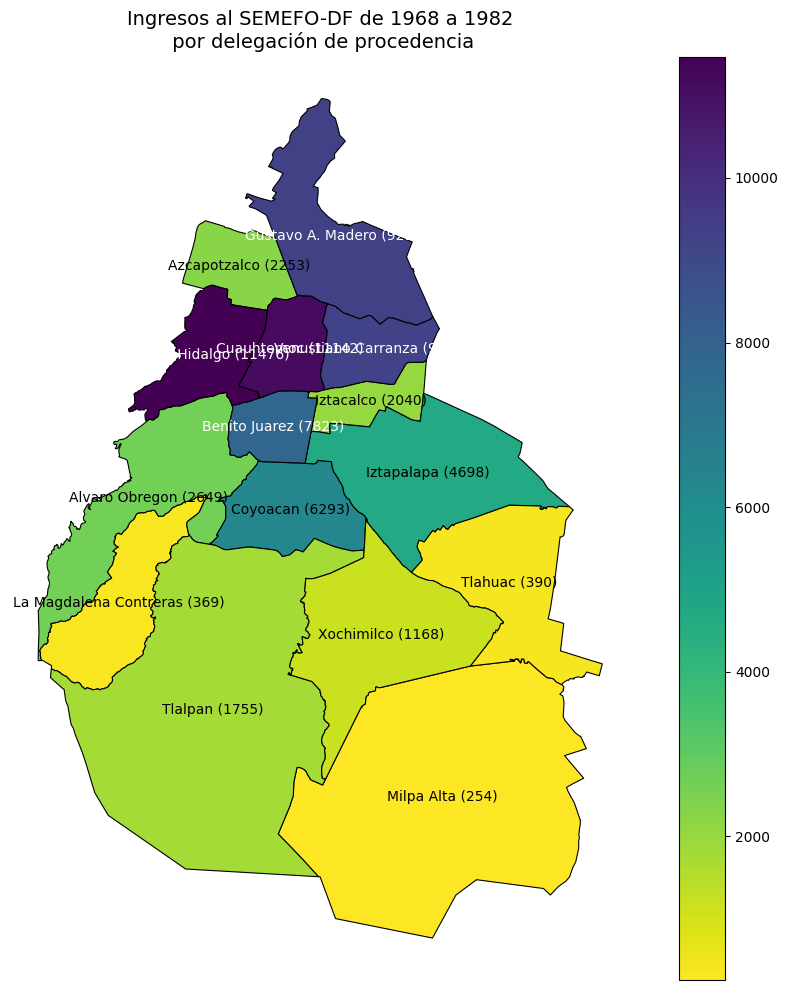

In [38]:
import geopandas as gpd

# capa de entidad y delegacion
mg_ent = gpd.read_file("catalogos/09_ciudaddemexico.zip!conjunto_de_datos", layer="09ent")
mg_mun = gpd.read_file("catalogos/09_ciudaddemexico.zip!conjunto_de_datos", layer="09mun")
mg_mun['NOMGEO'] = mg_mun['NOMGEO'].apply(unidecode)
mg_mun = mg_mun[['NOMGEO','geometry']]
mg_mun


# get freq
data = df['Procedencia_alcaldia'].value_counts(dropna=False).reset_index()
dic_rep = {'Gustavo A Madero':'Gustavo A. Madero', 'Magdalena Contreras':'La Magdalena Contreras', 'Cuajimalpa':'Cuajimalpa de Morelos'}
data['Procedencia_alcaldia'] = data['Procedencia_alcaldia'].replace(dic_rep)
data.columns = ['NOMGEO','freq']
# manage nan
nan_str, nan_otro = 'S-D', 'Otro'
data['NOMGEO'] = data['NOMGEO'].astype(str).replace({'nan':nan_str,nan:nan_str})
# filter 
data['NOMGEO'] = data['NOMGEO'].map({s:s for s in mg_mun['NOMGEO'].to_list() + [nan_str]}).fillna(nan_otro)
data = data.groupby('NOMGEO').sum().sort_index().reset_index()
# join with geometry
data = mg_mun.merge(data, on='NOMGEO')
display( data )

# plot figure
fig, ax = plt.subplots(figsize=(10, 10))
data.plot(column='freq', cmap='viridis_r', linewidth=0.8, edgecolor='black', legend=True, ax=ax)

# Crear etiqueta con nombre del municipio y frecuencia entre paréntesis
data['etiqueta'] = data['NOMGEO'] + ' (' + data['freq'].astype(str) + ')'

# Añadir nombres de municipios con frecuencia
for idx, row in data.iterrows():
    if row.geometry.centroid.is_empty: continue
    x, y = row.geometry.centroid.x, row.geometry.centroid.y
    color = 'white' if row['freq'] > 7500 else 'black'
    ax.text(x, y, row['etiqueta'], fontsize=10, 
            ha='center', va='center', 
            color=color)

ax.set_title('Ingresos al SEMEFO-DF de 1968 a 1982\n por delegación de procedencia', fontsize=14)
ax.axis('off')
plt.tight_layout()
#plt.savefig("imagenes/BO_Mapa_Ingresos.svg")
plt.show()

### Hospital y judicial

In [39]:
df['Procedencia_clasificacion'].value_counts()

Procedencia_clasificacion
Judicial             45501
Hospital             25139
Hospital+Judicial       85
Name: count, dtype: int64

## Proceso administrativo

'Numero_progresivo_transcrito', 
'Expediente_SEMEFO_transcrito',
'Foja_transcrito', 
'Observaciones'

### Numero_progresivo_transcrito

* El orden es por letra, luego fecha.
* Generalmente desconocidos, fetos, etc al final

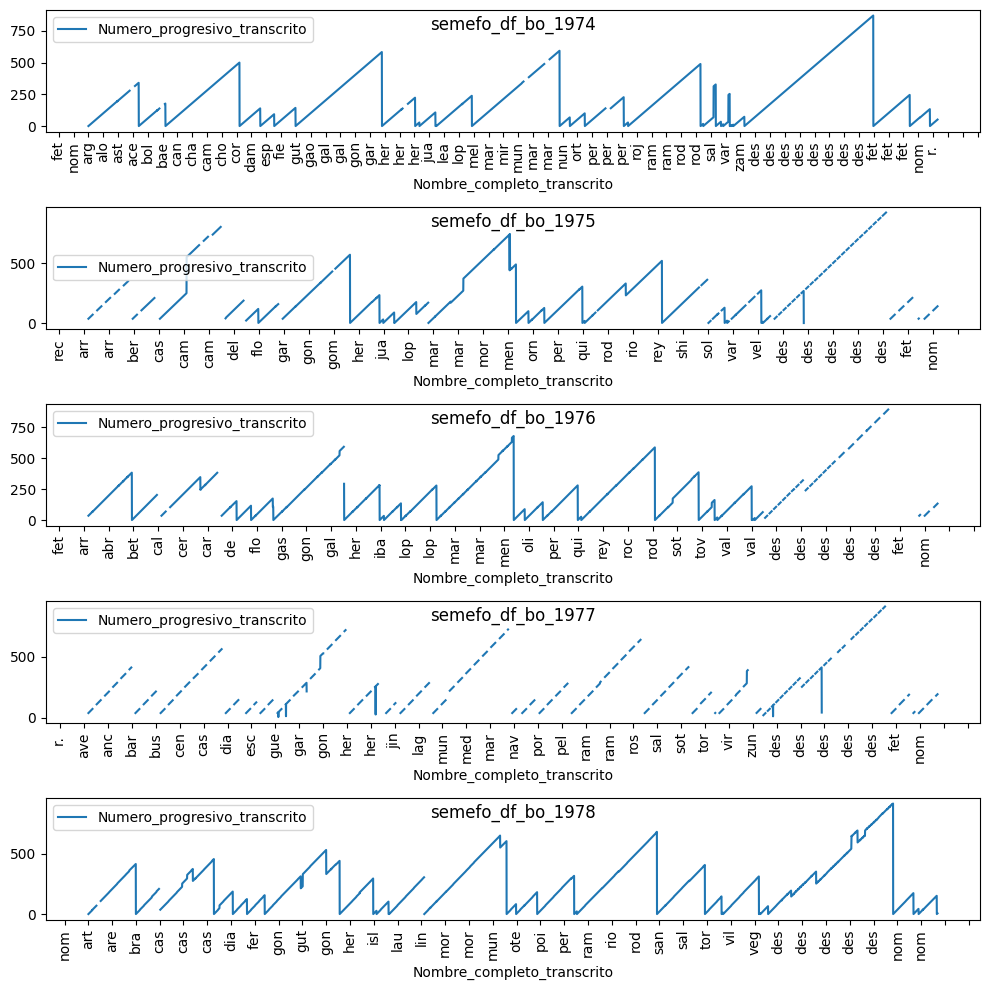

In [40]:
fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(10, 10))


i = 0
for bit in [f'semefo_df_bo_{i}' for i in range(1974, 1979)]:
    data = df.loc[(df['Bitacora_ingresos']==bit), ['Nombre_completo_transcrito','Numero_progresivo_transcrito']]
    if data.shape[0]>0:
        data['Nombre_completo_transcrito'] = data['Nombre_completo_transcrito'].apply(lambda s: s[0:3] if type(s)==str else nan)
        data['Numero_progresivo_transcrito'] = pd.to_numeric( data['Numero_progresivo_transcrito'].replace('S-D',nan) )
        data = data.set_index('Nombre_completo_transcrito')
        axes[i].set_title(bit, y=1.0, pad=-14)
        axes[i].locator_params(axis='x', nbins=70)
        #axes[i].get_legend().remove()
        data.plot(ax=axes[i], rot=90)
        i += 1
plt.tight_layout()
plt.show()

### Expediente_SEMEFO_transcrito

* El orden es por letra, luego fecha.
* De 1968 a 1973 en orden ortográfico + fecha
* De 1974 a 1982 desconocidos, fetos, etc al final

In [41]:
exp_sem = df[['Bitacora_ingresos','Nombre_completo_transcrito','Expediente_SEMEFO_transcrito']]
exp_sem.columns = ['Bitacora','Nombre','Exp']
exp_sem = to_dtype_with_errors(exp_sem, 'Exp', dtype='numeric', suffix='clean')
exp_sem

exp_sem['Exp_error'].unique()

array([nan, '1-/69', '759-Bis', '26/70', '27/70', '25/71',
       '1971-10-01 00:00:00', '2196 R', '85-72', '1972-12-01 00:00:00',
       '29-72', '30-72', '28-72', '61-71', '78-72', '(90235) 1', '82-81',
       '3549-Bis', '57/73', 'R.L', 'RL', '39/75', '60/75', '6329/73',
       'S/n', '34/75', '40/75', '4415 BIS', '251-76', '6725 Bis',
       '1080 Bis', '187-76', '3628 Bis', '250-76', '252-76', '6576 Bis',
       '2881 Bis', '6254 Bis', '136-Bis', '6900-75', '6903-75', '8/77',
       '1950 Bis', '323 Bis', '3014 bis', '1977-01-01 00:00:00',
       '2459-83', 'S-d', '359/78', '361/78', '371/78', '372/78', '362/78',
       '363/78', '379/78', '3092 Bis', '1.1/78', '1365 Bis', '5997 Bis',
       '364/78', '377/78', '366/78', '905 Bis', '376/78', '6249 bis',
       '360/78', '370/78', '374/78', '369/78', '375/78', '373/78',
       '378/78', '365/78', '801/79', '828/79', '831/79', '842/79',
       '824/79', '830/79', '-1-', '818/79', '827/79', '832/79', '834/79',
       '835-79', '7161-

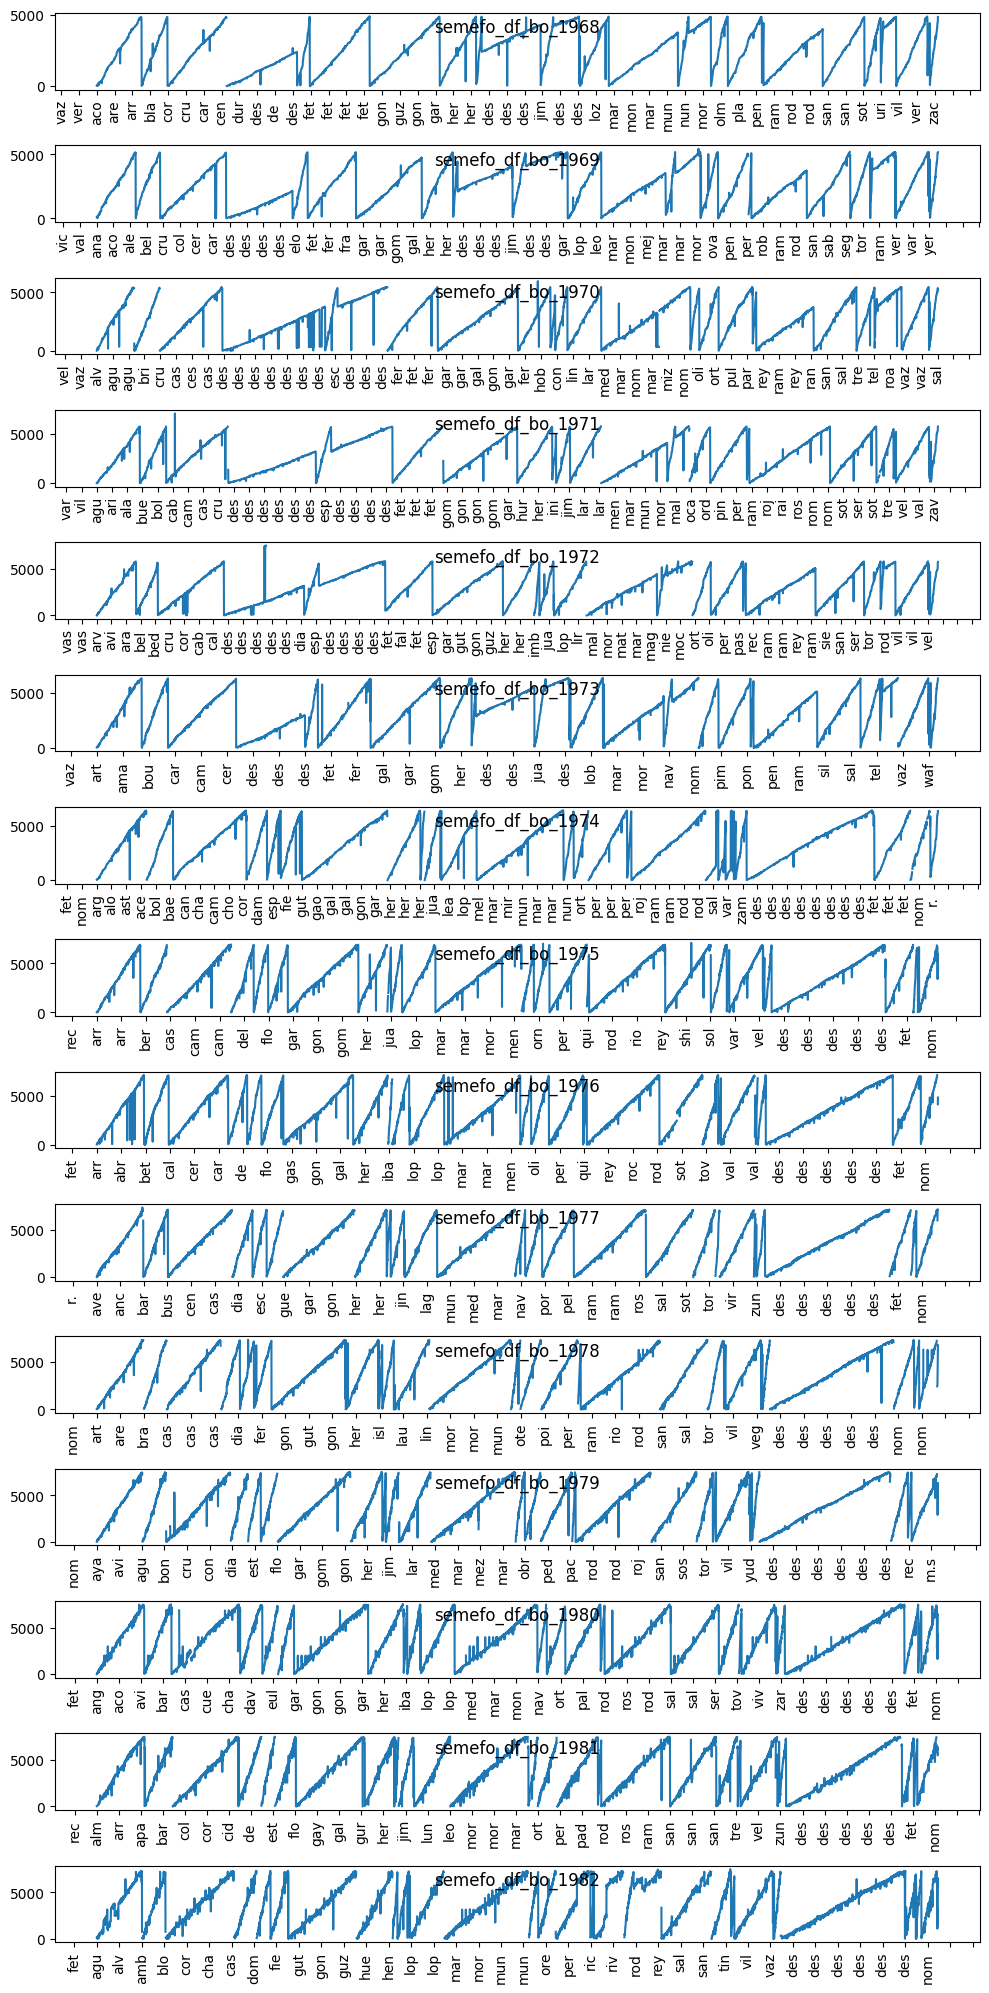

In [42]:
fig, axes = plt.subplots(nrows=15, ncols=1, figsize=(10, 20))

i = 0
for bit in [f'semefo_df_bo_{i}' for i in range(1968, 1983)]:
    data = exp_sem[(exp_sem['Bitacora']==bit)]
    if data.shape[0]>0:
        data['Nombre'] = data['Nombre'].apply(lambda s: s[0:3] if type(s)==str else nan)
        data.loc[data['Exp_clean']>=7500,'Exp_clean'] = nan
        data = data.set_index('Nombre')
        axes[i].set_title(bit, y=1.0, pad=-14)
        axes[i].locator_params(axis='x', nbins=70)
        data['Exp_clean'].plot(ax=axes[i], rot=90)
        axes[i].set_xlabel('')
        i += 1
plt.tight_layout()
plt.show()

### Foja_transcrito

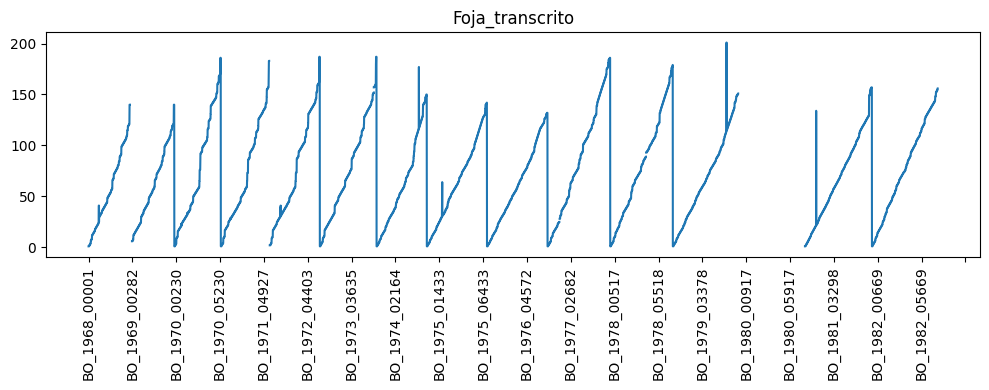

In [43]:
import re
get_digits = lambda s: int(re.findall(r'\d+',s)[0]) if type(s)==str else s
data = df['Foja_transcrito'].replace('S-D',nan).apply(get_digits)
data

fig, axes = plt.subplots(figsize=(10, 4))
axes.set_title('Foja_transcrito')
axes.locator_params(axis='x', nbins=30)
data.plot(ax=axes, rot=90)
axes.set_xlabel('')
plt.tight_layout()
plt.show()

### Observaciones

In [44]:
for tipo in df['Tipo_restos'].unique():
    print(tipo)
    display( df.loc[df['Tipo_restos']==tipo,'Observaciones'].value_counts().head(7) )
    print('\n\n')

Cadáver conocido


Observaciones
punto rojo en expediente_semefo                                                                              2417
punto rojo en expediente semefo                                                                              2087
punto rojo en numero_acta                                                                                     632
punto rojo en expediente semefo.                                                                              533
diagnostico no se ve completo                                                                                 268
de la foja 157 al 173 de esta bitacora hay registros de 1974, despues ya continuan los registros de 1973.     231
punto rojo en expediente_semefo; edad subrayada                                                               225
Name: count, dtype: int64




Cadáver desconocido


Observaciones
punto rojo en expediente_semefo                                               491
punto rojo en expediente semefo                                               261
punto rojo en expediente semefo.                                              258
marca de verificacion al final del nombre                                     234
punto rojo en numero_acta                                                     117
marca de verificacion al final del nombre; punto rojo en expediente_semefo     52
expediente_semefo no se ve completo.                                           52
Name: count, dtype: int64




Miembros


...

Observaciones
punto rojo en expediente_semefo                                                   35
punto rojo en expediente semefo                                                   26
en sexo de agrego un signo de interrogacion                                        8
el informe se entrego en una fecha posterior a la necropsia                        7
punto rojo en numero_acta                                                          7
cuadrito rojo enmarcando la fecha.                                                 7
punto rojo en expediente semefo diagnostico no se ve completo, no es inferecia     4
Name: count, dtype: int64




Restos óseos


Observaciones
osamenta                                                                4
no es posible inferir el sexo ya que no tenemos nombre_propio           2
no es posible inferir el sexo ya que no se cuenta con nombre propio     2
nota: sin autopsia. osamenta                                            1
no es posible inferir el sexo ya que no se cuenta con nombre_propio     1
osamenta (craneo y mandibula)                                           1
no es posible inferir el sexo ya que no se cuenta con nombre propio.    1
Name: count, dtype: int64




Recién nacido


Observaciones
punto rojo en expediente semefo                                                                                                                                                                                                                                                  8
cuadrito rojo enmarcando la fecha.                                                                                                                                                                                                                                               3
punto rojo en expediente_semefo                                                                                                                                                                                                                                                  3
nota: "nacida"                                                                                                                                                   

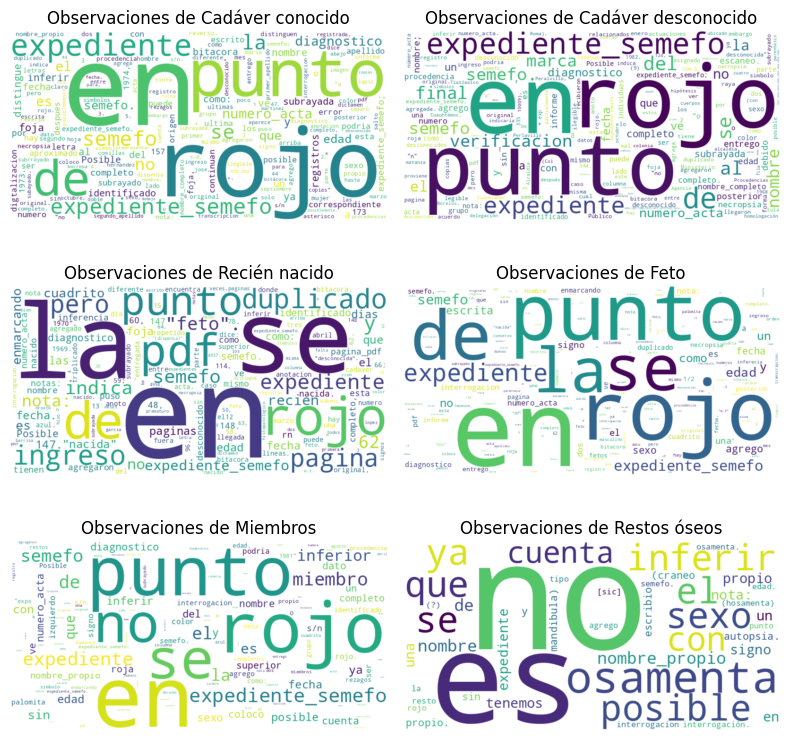

In [45]:
data = df.groupby('Tipo_restos').agg({'Observaciones':join_strings_with_nans})
data = data.to_dict()['Observaciones']
data

fig, axes = plt.subplots(nrows=3, ncols=2,figsize=(8,8))
axes = axes.flatten()

for ax,text in zip(axes,data.items()):
    # get word frequency
    freq = {}
    for word in text[1].split():
        freq[word] = freq.get(word, 0) + 1
    # create wordcloud
    wordcloud = WordCloud(width=800, height=400,
                          relative_scaling=0.5, 
                          background_color='white') \
                          .generate_from_frequencies(freq)
    # Display the word cloud
    ax.imshow(wordcloud, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(f"Observaciones de {text[0]}")

plt.tight_layout()
plt.show()